# E-Commerce Customer Segmentation using RFM
Applying K-Means and DBSCAN to segment customers based on Recency, Frequency, and Monetary (RFM) metrics. We will utilize PCA and t-SNE for dimensionality reduction and visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

# Set random seed for reproducibility
np.random.seed(42)

# Generate a synthetic RFM dataset representing 1000 customers
n_customers = 1000

# Recency (days since last purchase: 1 to 365)
recency = np.random.exponential(scale=100, size=n_customers).astype(int)
recency = np.clip(recency, 1, 365)

# Frequency (number of purchases: 1 to 100)
frequency = np.random.negative_binomial(n=5, p=0.2, size=n_customers) + 1

# Monetary (total spend: related to frequency with some noise)
monetary = frequency * np.random.normal(loc=50, scale=15, size=n_customers)
monetary = np.clip(monetary, 5, None)  # Ensure positive spend

rfm_df = pd.DataFrame({
    'CustomerID': range(1001, 1001 + n_customers),
    'Recency': recency,
    'Frequency': frequency,
    'Monetary': monetary
})

display(rfm_df.head())

,CustomerID,Recency,Frequency,Monetary
0,1001,46,24,640.065456
1,1002,301,11,804.710131
2,1003,131,31,1589.705704
3,1004,91,20,1522.712825
4,1005,16,12,969.807919


## Data Preprocessing
Scaling is crucial for distance-based algorithms like K-Means and DBSCAN. We will log-transform the features to handle right-skewness and then standardize them.

In [2]:
# Log transform to handle skewness
rfm_log = np.log1p(rfm_df[['Recency', 'Frequency', 'Monetary']])

# Standardize
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])
display(rfm_scaled_df.head())

,Recency,Frequency,Monetary
0,-0.136297,0.489192,-0.454926
1,1.406298,-1.049745,-0.105208
2,0.720009,1.006792,0.935425
3,0.420647,0.123620,0.869598
4,-0.979566,-0.881917,0.179967


## K-Means Clustering
We will find the optimal number of clusters using the Elbow Method and Silhouette Score.

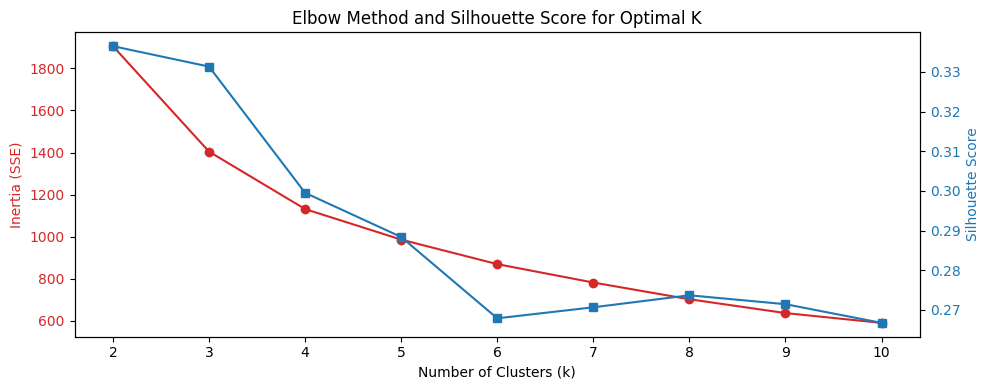

In [3]:
sse = []
sil_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    sse.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, kmeans.labels_))

fig, ax1 = plt.subplots(figsize=(10, 4))

color = 'tab:red'
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (SSE)', color=color)
ax1.plot(k_range, sse, marker='o', color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(k_range, sil_scores, marker='s', color=color)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Elbow Method and Silhouette Score for Optimal K')
fig.tight_layout()
plt.show()

Based on the metrics, we select `k=3` or `k=4` to fit our final K-Means model.

In [4]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm_df['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)
print(rfm_df['KMeans_Cluster'].value_counts())

KMeans_Cluster
2    455
0    313
1    232
Name: count, dtype: int64


## DBSCAN Clustering
DBSCAN is useful for finding clusters of arbitrary shape and identifying outliers (noise labeled as `-1`).

In [5]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
rfm_df['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)
print(rfm_df['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 0    946
-1     54
Name: count, dtype: int64


## Dimensionality Reduction & Visualization (PCA & t-SNE)

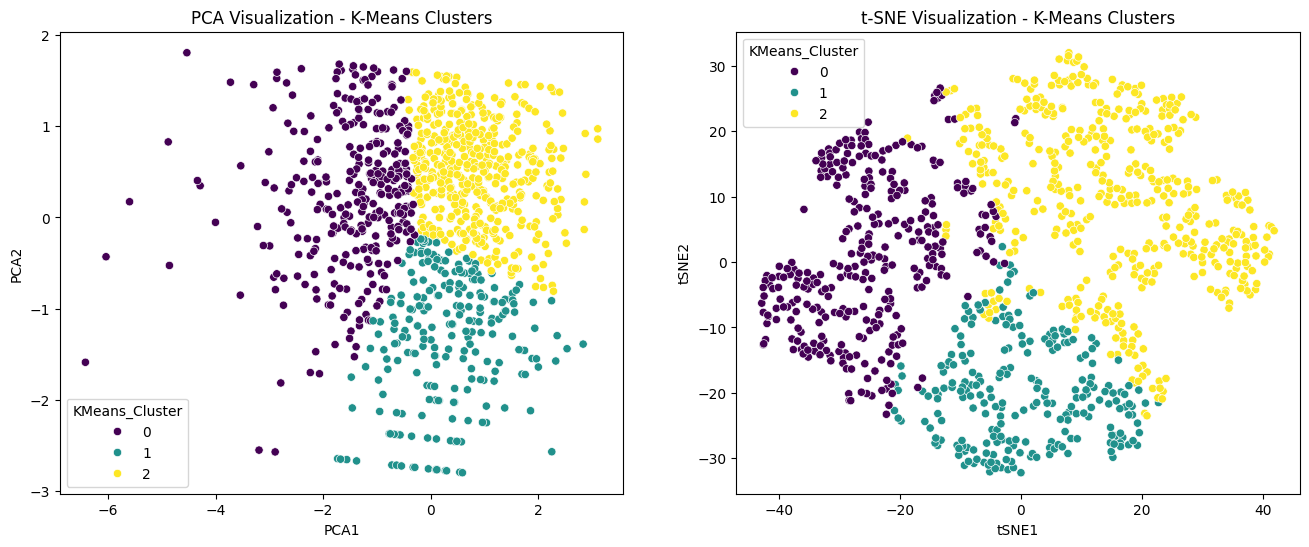

In [6]:
# PCA
pca = PCA(n_components=2)
pca_comps = pca.fit_transform(rfm_scaled)
rfm_df['PCA1'] = pca_comps[:, 0]
rfm_df['PCA2'] = pca_comps[:, 1]

# t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_comps = tsne.fit_transform(rfm_scaled)
rfm_df['tSNE1'] = tsne_comps[:, 0]
rfm_df['tSNE2'] = tsne_comps[:, 1]

# Plotting results side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x='PCA1', y='PCA2', hue='KMeans_Cluster', data=rfm_df, palette='viridis', ax=axes[0])
axes[0].set_title('PCA Visualization - K-Means Clusters')

sns.scatterplot(x='tSNE1', y='tSNE2', hue='KMeans_Cluster', data=rfm_df, palette='viridis', ax=axes[1])
axes[1].set_title('t-SNE Visualization - K-Means Clusters')

plt.show()

## Persona Profiling & Actionable Marketing Insights

In [7]:
# Calculate cluster profiles based on original RFM scales
profile = rfm_df.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(1)
profile['Count'] = rfm_df.groupby('KMeans_Cluster').size()
display(profile)

,Recency,Frequency,Monetary,Count
KMeans_Cluster,,,,
0,98.8,11.5,488.9,313
1,14.3,22.6,1163.3,232
2,133.2,26.7,1333.3,455
